--- Starting GA with Max Generations: 100 | Patience: 25 ---
Gen   1 | Best Fitness: 3.84960 | Patience Left: 25
Gen   5 | Best Fitness: 3.85026 | Patience Left: 23
Gen  10 | Best Fitness: 3.85026 | Patience Left: 18
Gen  15 | Best Fitness: 3.85026 | Patience Left: 13
Gen  20 | Best Fitness: 3.85027 | Patience Left: 25
Gen  25 | Best Fitness: 3.85027 | Patience Left: 20
Gen  30 | Best Fitness: 3.85027 | Patience Left: 15
Gen  35 | Best Fitness: 3.85027 | Patience Left: 10
Gen  40 | Best Fitness: 3.85027 | Patience Left: 5
Gen  45 | Best Fitness: 3.85027 | Patience Left: 0

[EARLY STOPPING TRIGGERED] No significant improvement (> 1e-05) for 25 consecutive generations.
Terminating optimization at Generation 45 out of 100.

================ FINAL RESULT ================
Stopped at Generation: 45/100
Optimal x found: 1.850492
Maximum f(x) value: 3.850271


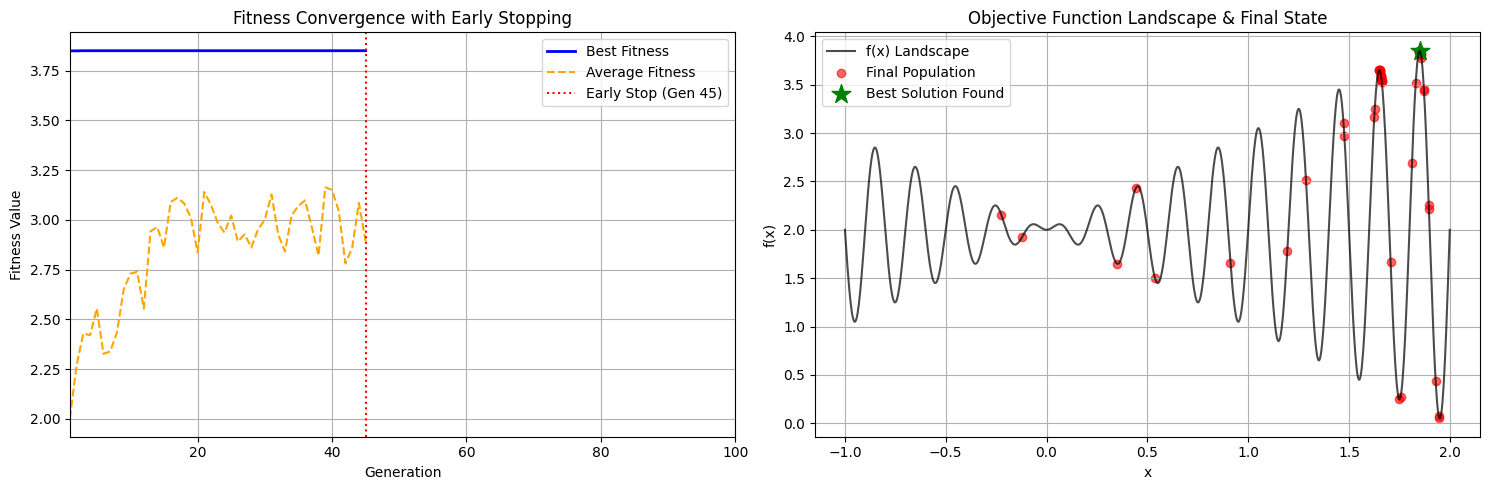

In [ ]:
import numpy as np
import random
import matplotlib.pyplot as plt

# -------------------------------------------------------------------
# STEP 1: Define the Problem
# Objective: Maximize f(x) = x * sin(10 * pi * x) + 2.0 over [-1, 2]
# -------------------------------------------------------------------
def objective_function(x):
    return x * np.sin(10 * np.pi * x) + 2.0

# -------------------------------------------------------------------
# STEP 2: Initialize Parameters (including Early Stopping)
# -------------------------------------------------------------------
POPULATION_SIZE = 50   # Number of individuals
GENE_LENGTH = 16        # Precision bits for binary encoding
CROSSOVER_RATE = 0.8    # Crossover probability
MUTATION_RATE = 0.05    # Mutation probability per bit
MAX_GENERATIONS = 100   # Maximum limit of iterations
X_MIN, X_MAX = -1.0, 2.0  # Search space boundaries

# Early Stopping Parameters
PATIENCE = 25          # Max generations to wait for improvement before stopping
MIN_DELTA = 1e-5       # Minimum improvement threshold to reset patience

# Helper: Convert Binary Chromosome to Real Value x
def decode_chromosome(chromosome):
    binary_str = ''.join(map(str, chromosome))
    decimal_val = int(binary_str, 2)
    max_decimal = (2 ** GENE_LENGTH) - 1
    return X_MIN + (decimal_val / max_decimal) * (X_MAX - X_MIN)

# -------------------------------------------------------------------
# STEP 3: Create Initial Population
# -------------------------------------------------------------------
def create_initial_population():
    return [np.random.randint(0, 2, size=GENE_LENGTH).tolist() for _ in range(POPULATION_SIZE)]

# -------------------------------------------------------------------
# STEP 4: Evaluate Fitness
# -------------------------------------------------------------------
def evaluate_fitness(population):
    return [objective_function(decode_chromosome(ind)) for ind in population]

# -------------------------------------------------------------------
# STEP 5: Selection (Roulette Wheel)
# -------------------------------------------------------------------
def select_parent(population, fitness_scores):
    min_fitness = min(fitness_scores)
    adjusted_fitness = [f - min_fitness + 1e-6 for f in fitness_scores]
    total_fitness = sum(adjusted_fitness)
    probabilities = [f / total_fitness for f in adjusted_fitness]
    selected_idx = np.random.choice(len(population), p=probabilities)
    return population[selected_idx]

# -------------------------------------------------------------------
# STEP 6: Crossover
# -------------------------------------------------------------------
def crossover(parent1, parent2):
    if random.random() < CROSSOVER_RATE:
        pt = random.randint(1, GENE_LENGTH - 1)
        return parent1[:pt] + parent2[pt:], parent2[:pt] + parent1[pt:]
    return parent1.copy(), parent2.copy()

# -------------------------------------------------------------------
# STEP 7: Mutation
# -------------------------------------------------------------------
def mutate(individual):
    for i in range(len(individual)):
        if random.random() < MUTATION_RATE:
            individual[i] = 1 - individual[i]
    return individual

# -------------------------------------------------------------------
# STEP 8 & 9: Main Loop with Early Stopping Implementation
# -------------------------------------------------------------------
def run_ga_with_early_stopping():
    population = create_initial_population()

    best_fitness_history = []
    avg_fitness_history = []

    best_overall_fitness = -float('inf')
    best_overall_chromosome = None

    # Early Stopping state tracking
    no_improvement_counter = 0
    stopped_generation = MAX_GENERATIONS

    print(f"--- Starting GA with Max Generations: {MAX_GENERATIONS} | Patience: {PATIENCE} ---")

    for gen in range(1, MAX_GENERATIONS + 1):
        fitness_scores = evaluate_fitness(population)

        current_best = max(fitness_scores)
        current_avg = np.mean(fitness_scores)
        best_fitness_history.append(current_best)
        avg_fitness_history.append(current_avg)

        # ---------------------------------------------------------------
        # EARLY STOPPING CHECK
        # ---------------------------------------------------------------
        if current_best > best_overall_fitness + MIN_DELTA:
            best_overall_fitness = current_best
            best_overall_chromosome = population[fitness_scores.index(current_best)]
            no_improvement_counter = 0  # Reset patience counter
        else:
            no_improvement_counter += 1  # Increment patience counter

        # Print progress update
        if gen % 5 == 0 or gen == 1:
            print(f"Gen {gen:3d} | Best Fitness: {best_overall_fitness:.5f} | Patience Left: {PATIENCE - no_improvement_counter}")

        # Check if early stopping condition is met
        if no_improvement_counter >= PATIENCE:
            stopped_generation = gen
            print(f"\n[EARLY STOPPING TRIGGERED] No significant improvement (> {MIN_DELTA}) for {PATIENCE} consecutive generations.")
            print(f"Terminating optimization at Generation {stopped_generation} out of {MAX_GENERATIONS}.")
            break

        # Reproduce Next Generation
        next_gen = [population[fitness_scores.index(current_best)].copy()] # Elitism

        while len(next_gen) < POPULATION_SIZE:
            p1 = select_parent(population, fitness_scores)
            p2 = select_parent(population, fitness_scores)
            c1, c2 = crossover(p1, p2)
            next_gen.append(mutate(c1))
            if len(next_gen) < POPULATION_SIZE:
                next_gen.append(mutate(c2))

        population = next_gen

    best_x = decode_chromosome(best_overall_chromosome)
    final_population_x = [decode_chromosome(ind) for ind in population]
    final_population_y = [objective_function(x) for x in final_population_x]

    # Print Summary
    print("\n================ FINAL RESULT ================")
    print(f"Stopped at Generation: {stopped_generation}/{MAX_GENERATIONS}")
    print(f"Optimal x found: {best_x:.6f}")
    print(f"Maximum f(x) value: {best_overall_fitness:.6f}")
    print("=============================================")

    # -------------------------------------------------------------------
    # VISUALIZATION PLOTS
    # -------------------------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # Plot 1: Convergence with Early Stopping Marker
    axes[0].plot(range(1, stopped_generation + 1), best_fitness_history, label="Best Fitness", color="blue", linewidth=2)
    axes[0].plot(range(1, stopped_generation + 1), avg_fitness_history, label="Average Fitness", color="orange", linestyle="--")
    axes[0].axvline(x=stopped_generation, color='red', linestyle=':', label=f'Early Stop (Gen {stopped_generation})')
    axes[0].set_title("Fitness Convergence with Early Stopping")
    axes[0].set_xlabel("Generation")
    axes[0].set_ylabel("Fitness Value")
    axes[0].set_xlim(1, MAX_GENERATIONS)  # Shows remaining unused generations on axis
    axes[0].legend()
    axes[0].grid(True)

    # Plot 2: Objective Function Landscape
    x_space = np.linspace(X_MIN, X_MAX, 1000)
    y_space = objective_function(x_space)

    axes[1].plot(x_space, y_space, color="black", label="f(x) Landscape", alpha=0.7)
    axes[1].scatter(final_population_x, final_population_y, color="red", alpha=0.6, label="Final Population")
    axes[1].scatter([best_x], [best_overall_fitness], color="green", marker="*", s=200, label="Best Solution Found")
    axes[1].set_title("Objective Function Landscape & Final State")
    axes[1].set_xlabel("x")
    axes[1].set_ylabel("f(x)")
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()

# Run the algorithm
run_ga_with_early_stopping()
